# OpsPilot AI — Model 1: Ticket Delay Risk Prediction (v2, improved)

Looks at a help-desk ticket **at the moment it is created** and estimates the probability that it will take **longer than a chosen number of hours** to resolve.

**What changed from v1 (and why)** — your first run showed ROC-AUC ≈ 0.58 and a model that lost to "predict everything is delayed". The causes and fixes:

| Problem seen in v1 | Fix in v2 |
|---|---|
| 48 h threshold made 84 % of tickets "delayed" (median ticket takes ~35 days) | Notebook **tests several thresholds** on validation data and picks one with a balanced, stable class split (you can force your own) |
| Share of delayed tickets drifted 89 % → 76 % → 67 % over time | **Open tickets already past the threshold are now labelled delayed** (v1 threw them away, hiding the slow ones); plus **recent-trend features** and **recency-weighted training** |
| `reporter` (thousands of IDs) dominated and memorised people | Reporter is now turned into **leakage-safe history features** (their past ticket count and past delay rate) instead of one-hot columns |
| `project` column was not detected | Column names are now **set explicitly** for this dataset |
| Train/validation boundary could share "future" outcomes | A **label embargo** removes tickets whose outcome wasn't yet known at the split date |
| Basic XGBoost settings | XGBoost now uses **early stopping** on validation and a wider tuned search |

**How to read it (beginner tip):** *Run All*. Each section explains first, then runs code. You normally only edit the **Config** cell.

### Kaggle setup (same as before)
Attach your `help-desk-tickets` dataset with **Add Input**. The notebook finds `issues.csv` automatically.

### Rules this notebook follows
* **No leakage** – only information known when the ticket is created is used. Never used: assignee, status, resolution, comment counts, `started`/`ended`, all `wf_*` step times, `processing_steps`.
* **Time-aware split** – oldest 70 % train, next 15 % validation, newest 15 % test (scored once).
* **Honest reporting** – nothing is claimed until it has been computed in your run.

## v3 changes (read first)

1. **`START_DATE` filter** (Config + section 3): tickets created before 2016 are ignored, because every pre-2015 ticket is labelled delayed.
2. **New features** (section 5): `project_priority` history, `*_gap_hrs` (hours since the previous ticket in the group) and `*_recent_log_hrs` (how long recently resolved tickets took). All are time-safe; the built-in leakage and time-safety checks still run.
3. Old saved outputs were cleared, so **Run All** to get fresh numbers. Compare them with v2 on **validation first**; look at the test table only once.


## 1. Setup and imports

In [1]:
import itertools, json, logging, warnings
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss, classification_report,
                             confusion_matrix, f1_score, precision_recall_curve,
                             precision_score, recall_score, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
try:
    from lightgbm import LGBMClassifier
    HAS_LGBM = True
except ImportError:
    HAS_LGBM = False
try:
    import shap
    HAS_SHAP = True
except ImportError:
    HAS_SHAP = False

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
logging.basicConfig(level=logging.INFO, format="%(asctime)s | %(levelname)s | %(message)s", force=True)
logger = logging.getLogger("delay_risk")
logger.info("XGBoost: %s | LightGBM: %s | SHAP: %s", HAS_XGB, HAS_LGBM, HAS_SHAP)

2026-10-28 13:30:23,382 | INFO | XGBoost: True | LightGBM: True | SHAP: True


## 2. Config (the only cell you should need to edit)

**Threshold:** with `THRESHOLD_MODE = "auto"` the notebook tries every value in `THRESHOLD_CANDIDATES_HOURS`, trains a quick model for each on the **training** data, scores it on **validation** data, and keeps those whose class split is balanced and stable over time, and picks the best ROC-AUC (when several are within 0.01 of each other, it takes the most balanced one, because differences that small are noise). If your business has a real SLA (e.g. "7 days"), set `THRESHOLD_MODE = "fixed"` and put it in `RESOLUTION_TIME_THRESHOLD_HOURS` — a real SLA beats a statistically convenient number.

In [2]:
# ============================ CONFIG ============================
# --- the target ---
THRESHOLD_MODE = "auto"                    # "auto" = pick from candidates | "fixed" = use the value below
RESOLUTION_TIME_THRESHOLD_HOURS = 168      # used when mode = "fixed" (auto overwrites it with its choice)
THRESHOLD_CANDIDATES_HOURS = [24, 48, 72, 168, 336, 720, 1440]
SHOW_THRESHOLD_SWEEP = True                # also print the sweep table in "fixed" mode
PREV_RANGE = (0.20, 0.80)                  # auto-mode only considers thresholds with this share of delayed tickets in TRAIN
MAX_PREV_DRIFT = 0.20                      # ...and |delayed share in validation - in train| <= this
ROC_TIE_TOLERANCE = 0.01                   # thresholds within this ROC-AUC of the best count as tied -> prefer the most balanced one

# --- NEW in v3: ignore very old tickets ---
# In this dataset EVERY ticket created before 2015 is "delayed" (share = 1.0), which teaches the model a fake
# rule ("old = delayed"). Only tickets created on/after START_DATE are used. Try "2015-01-01" and "2016-01-01"
# and keep whichever gives the better VALIDATION numbers. Set to None to use everything (old behaviour).
START_DATE = "2016-01-01"

# --- general ---
RANDOM_STATE = 42
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15          # test = remaining 15 % (most recent)
MODEL_VERSION = "delay-risk-v3"
FAST_MODE = False                          # True = smaller search, much quicker (use to debug)

# --- risk bands shown to humans ---
RISK_LOW_BELOW, RISK_HIGH_FROM = 0.4, 0.7  # low < 0.4 <= medium < 0.7 <= high

# --- decision threshold goal: "high_recall" | "high_precision" | "f1" ---
OPERATIONAL_GOAL = "high_recall"
TARGET_RECALL = 0.80
TARGET_PRECISION = 0.70

# --- features ---
MIN_CATEGORY_COUNT = 20        # rarer categories are grouped when one-hot encoding
SMOOTHING = 10                 # pulls small-sample history rates toward the overall rate
RECENT_WINDOW_DAYS = 90        # "recent trend" features look at outcomes known in the last N days
USE_REPORTER_ONEHOT = False    # False = reporter only used through history features (recommended)
HALF_LIFE_CHOICES_DAYS = [None, 1095]   # recency weighting candidates for training (None = equal weights)

# --- the data (names set for the Mendeley Help Desk Tickets issues.csv) ---
ISSUES_FILE = "issues.csv"
RESOLUTION_NUMERIC_UNIT = "seconds"   # only used if the resolution column is a plain number
COLUMN_OVERRIDES: Dict[str, Optional[str]] = {
    "ticket_id": "id", "created": "issue_created", "resolved": "issue_resolution_date",
    "priority": "issue_priority", "category": "issue_type", "project": "issue_proj",
    "reporter": "issue_reporter", "country": None, "text": None,
}   # set a value to None to auto-detect it instead

UNIT_TO_HOURS = {"seconds": 1 / 3600, "minutes": 1 / 60, "hours": 1.0, "days": 24.0}
ON_KAGGLE = Path("/kaggle/working").exists()
ARTIFACT_DIR = Path("/kaggle/working/artifacts") if ON_KAGGLE else Path("ml/artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
print("Artifacts will be saved to:", ARTIFACT_DIR.resolve())

Artifacts will be saved to: /kaggle/working/artifacts


## 3. Inspect the dataset

File names, shapes, column types, sample rows, missing values and duplicates — before any modelling.

In [3]:
def find_data_files() -> Dict[str, Path]:
    """Find all .csv/.xlsx files under /kaggle/input or data/raw."""
    found: Dict[str, Path] = {}
    for root in (Path("/kaggle/input"), Path("data/raw")):
        if root.exists():
            for p in sorted(root.rglob("*")):
                if p.suffix.lower() in {".csv", ".xlsx"}:
                    found.setdefault(p.name, p)
    return found


def parse_dt(s: pd.Series) -> pd.Series:
    """Parse to timezone-naive UTC datetimes. Bad values become NaT (never crash)."""
    try:
        out = pd.to_datetime(s, errors="coerce", utc=True, format="mixed")
    except (TypeError, ValueError):
        out = pd.to_datetime(s, errors="coerce", utc=True)
    return out.dt.tz_localize(None)


DATA_FILES = find_data_files()
if not DATA_FILES:
    raise FileNotFoundError("No data files found. On Kaggle: click 'Add Input' and attach your dataset. "
                            "Locally: put the CSVs in data/raw/.")
print("Files found:")
for n, p in DATA_FILES.items():
    print("  ", n, "->", p)

raw_frames: Dict[str, pd.DataFrame] = {}
for name, path in DATA_FILES.items():
    if path.suffix.lower() != ".csv":
        print(f"\n(skipping non-CSV file: {name})")
        continue
    df_ = pd.read_csv(path, low_memory=False, encoding_errors="replace")
    raw_frames[name] = df_
    print("\n" + "=" * 90)
    print(f"{name}   shape = {df_.shape}")
    print("-" * 90)
    print(df_.dtypes.to_string())
    display(df_.head(3))
    miss = df_.isna().sum()
    print("Columns with missing values (top 10):", miss[miss > 0].sort_values(ascending=False).head(10).to_dict())
    print("Exact duplicate rows:", int(df_.duplicated().sum()))

Files found:
   issues.csv -> /kaggle/input/datasets/daylight19/help-desk-tickets/issues.csv

issues.csv   shape = (66691, 58)
------------------------------------------------------------------------------------------
id                               float64
started                           object
ended                             object
issue_num                        float64
issue_proj                        object
issue_reporter                    object
issue_assignee                    object
issue_contr_count                float64
issue_type                        object
issue_priority                    object
issue_created                     object
issue_resolution_date             object
issue_resolution                  object
issue_status                      object
issue_comments_count               int64
last_change_date                  object
wf_in_review                     float64
wfe_in_review                      int64
wf_deployment                    float64
wfe

,id,started,ended,issue_num,issue_proj,issue_reporter,issue_assignee,issue_contr_count,issue_type,issue_priority,...,wf_cancelled,wfe_cancelled,wf_under_review,wfe_under_review,wf_approved,wfe_approved,wf_pending_deployment,wfe_pending_deployment,wf_total_time,processing_steps
0,11887.0,2016-01-06 08:23:43+00:00,2016-01-06 08:56:55+00:00,186.0,d1z0,4olg,NaN,1.0,Ticket,Medium,...,NaN,0,NaN,0,NaN,0,NaN,0,1992.0,2
1,11890.0,2016-01-11 10:06:19+00:00,2016-01-12 12:30:23+00:00,190.0,d1z0,4olg,NaN,1.0,Ticket,Medium,...,NaN,0,NaN,0,NaN,0,NaN,0,95044.0,2
2,11904.0,2016-01-21 07:28:20+00:00,2016-01-26 08:21:47+00:00,198.0,d1z0,4ohk,4ohk,1.0,Ticket,Medium,...,NaN,0,NaN,0,NaN,0,NaN,0,435207.0,2


Columns with missing values (top 10): {'wf_in_review': 66614, 'wf_rejected': 66579, 'wf_deployment': 66556, 'wf_cancelled': 66531, 'wf_pending_customer_approval': 66437, 'wf_testing_monitoring': 66401, 'wf_monitoring': 66173, 'wf_to_do': 65906, 'wf_done': 65831, 'wf_pending_deployment': 65278}
Exact duplicate rows: 0


In [4]:
if ISSUES_FILE not in raw_frames:
    raise FileNotFoundError(f"'{ISSUES_FILE}' not found. Available CSVs: {list(raw_frames)}. Change ISSUES_FILE in Config.")
raw = raw_frames[ISSUES_FILE]

# NEW in v3: drop very old tickets (see START_DATE in Config)
if START_DATE is not None:
    _created_col = COLUMN_OVERRIDES.get("created") or "issue_created"
    _keep = parse_dt(raw[_created_col]) >= pd.Timestamp(START_DATE)
    print(f"START_DATE filter: keeping {int(_keep.sum()):,} of {len(raw):,} tickets (created on/after {START_DATE})")
    raw = raw[_keep].reset_index(drop=True)


def summarize_columns(df: pd.DataFrame) -> Dict[str, List[str]]:
    """Split columns into datetime / numeric / categorical-or-text."""
    dt_cols, num_cols, cat_cols = [], [], []
    for c in df.columns:
        s = df[c]
        if pd.api.types.is_datetime64_any_dtype(s):
            dt_cols.append(c)
        elif pd.api.types.is_numeric_dtype(s):
            num_cols.append(c)
        else:
            sample = s.dropna().astype(str).head(300)
            looks_numeric = sample.str.fullmatch(r"-?\d+(\.\d+)?").any() if len(sample) else False
            if len(sample) and not looks_numeric and parse_dt(sample).notna().mean() > 0.9:
                dt_cols.append(c)
            else:
                cat_cols.append(c)
    return {"datetime": dt_cols, "numeric": num_cols, "categorical/text": cat_cols}


col_types = summarize_columns(raw)
for k, v in col_types.items():
    print(f"{k:>16} ({len(v)}): {v if len(v) < 12 else v[:12] + ['...']}")
print("\nCandidate target/time columns:",
      [c for c in raw.columns if any(w in c.lower() for w in ("resol", "close", "ended", "duration", "total_time"))])

KEYWORDS: Dict[str, Tuple[List[str], List[str]]] = {
    "ticket_id": (["issue_id", "ticket_id", "id", "key", "issue_key"], []),
    "created":   (["created_at", "created", "creation_time", "start_time", "reported_at", "opened_at"], ["second"]),
    "resolved":  (["resolved_at", "resolution_time", "resolution_date", "resolved", "closed_at", "end_time"], ["second", "step"]),
    "priority":  (["priority", "severity"], []),
    "category":  (["category", "type"], []),
    "project":   (["project", "product", "proj"], []),
    "reporter":  (["reporter", "reported_by", "requester", "customer"], []),
    "country":   (["country"], []),
    "text":      (["summary", "title", "subject", "description"], []),
}


def detect_column(columns, names: List[str], exclude: List[str]) -> Optional[str]:
    """Exact name match first, then partial match. Returns None if nothing fits."""
    lowered = {c.lower(): c for c in columns}
    for n in names:
        if n in lowered:
            return lowered[n]
    for n in names:
        for low, orig in lowered.items():
            if n in low and not any(e in low for e in exclude):
                return orig
    return None


mapping: Dict[str, Optional[str]] = {}
for logical, (names, excl) in KEYWORDS.items():
    override = COLUMN_OVERRIDES.get(logical)
    if override is not None and override not in raw.columns:
        raise KeyError(f"COLUMN_OVERRIDES['{logical}']='{override}' is not a column of {ISSUES_FILE}.")
    mapping[logical] = override or detect_column(raw.columns, names, excl)

print("\nColumn mapping (logical name -> column in your file):")
for k, v in mapping.items():
    print(f"  {k:>10} -> {v}")
if mapping["created"] is None or mapping["resolved"] is None:
    raise ValueError("Could not find the creation and/or resolution columns. Set COLUMN_OVERRIDES in Config.")
if mapping["created"] == mapping["resolved"]:
    raise ValueError("'created' and 'resolved' point to the same column. Fix COLUMN_OVERRIDES.")

used = {v for v in mapping.values() if v}
print(f"\n{len(raw.columns) - len(used)} columns are deliberately NOT used (known only after creation / during or after the work), e.g.:")
print([c for c in raw.columns if c not in used][:14], "...")

START_DATE filter: keeping 42,974 of 66,691 tickets (created on/after 2016-01-01)
        datetime (5): ['started', 'ended', 'issue_created', 'issue_resolution_date', 'last_change_date']
         numeric (46): ['id', 'issue_num', 'issue_contr_count', 'issue_comments_count', 'wf_in_review', 'wfe_in_review', 'wf_deployment', 'wfe_deployment', 'wf_resolved', 'wfe_resolved', 'wf_open', 'wfe_open', '...']
categorical/text (7): ['issue_proj', 'issue_reporter', 'issue_assignee', 'issue_type', 'issue_priority', 'issue_resolution', 'issue_status']

Candidate target/time columns: ['ended', 'issue_resolution_date', 'issue_resolution', 'wf_resolved', 'wfe_resolved', 'wf_resolved_under_monitoring', 'wfe_resolved_under_monitoring', 'wf_closed', 'wfe_closed', 'wf_total_time']

Column mapping (logical name -> column in your file):
   ticket_id -> id
     created -> issue_created
    resolved -> issue_resolution_date
    priority -> issue_priority
    category -> issue_type
     project -> issue_proj
 

## 4. Target definition (functions)

* **Prediction time** = ticket creation time.
* **actual_resolution_time (hours)** = resolution timestamp − creation timestamp.
* **delayed** = 1 if that time is **greater than** the threshold, else 0.

**New in v2 – open tickets.** A ticket with *no* resolution yet, whose age at the end of the data already exceeds the threshold, **is delayed** (we know it, even without a resolution date) → label 1. If it's still younger than the threshold, we can't know yet → excluded. v1 dropped all open tickets, which made recent periods look better than reality.

**Excluded:** no valid creation time, negative duration, open tickets younger than the threshold. Exact duplicate rows are removed first.

In [5]:
def _clean_id(s: pd.Series) -> pd.Series:
    """11887.0 -> '11887'"""
    if pd.api.types.is_float_dtype(s) and s.dropna().mod(1).eq(0).all():
        return s.astype("Int64").astype(str)
    return s.astype(str)


def standardize(df: pd.DataFrame, mapping: Dict[str, Optional[str]], threshold_hours: float,
                numeric_unit: str = "seconds") -> pd.DataFrame:
    """Standard column names, parsed times and the target.

    resolved_ts / resolution_hours / delayed / known_ts describe the OUTCOME. They are used only to build the
    label and the time-safe history features - never as direct model inputs.
    known_ts = the moment the outcome becomes known: created + threshold for delayed tickets (we know it the
    instant the threshold passes), or the resolution time for on-time tickets.
    """
    out = pd.DataFrame(index=df.index)
    out["ticket_id"] = _clean_id(df[mapping["ticket_id"]]) if mapping.get("ticket_id") else df.index.astype(str)
    for logical in ["priority", "category", "project", "reporter", "country", "text"]:
        if mapping.get(logical):
            out[logical] = df[mapping[logical]]
    out["created_ts"] = parse_dt(df[mapping["created"]])

    res = df[mapping["resolved"]]
    if pd.api.types.is_numeric_dtype(res):
        hours = pd.to_numeric(res, errors="coerce") * UNIT_TO_HOURS[numeric_unit]
        resolved_ts = out["created_ts"] + pd.to_timedelta(hours, unit="h")
    else:
        resolved_ts = parse_dt(res)
        hours = (resolved_ts - out["created_ts"]).dt.total_seconds() / 3600.0

    invalid = (hours < 0).fillna(False)
    out["invalid_duration"] = invalid
    out["resolution_hours"] = hours.mask(invalid)
    out["resolved_ts"] = resolved_ts.mask(invalid)
    out["delayed"] = (out["resolution_hours"] > threshold_hours).astype(float).where(out["resolution_hours"].notna())
    thr = pd.Timedelta(hours=threshold_hours)
    out["known_ts"] = out["resolved_ts"].where(out["delayed"].eq(0), out["created_ts"] + thr).where(out["delayed"].notna())
    out["label_from_open_ticket"] = False
    return out


def apply_open_ticket_rule(std: pd.DataFrame, threshold_hours: float, observation_end: pd.Timestamp) -> pd.DataFrame:
    """Still-open tickets that are already older than the threshold at the end of the data are delayed."""
    thr = pd.Timedelta(hours=threshold_hours)
    open_mask = std["delayed"].isna() & ~std["invalid_duration"] & std["resolved_ts"].isna() & std["created_ts"].notna()
    exceeded = open_mask & ((observation_end - std["created_ts"]) > thr)
    std.loc[exceeded, "delayed"] = 1.0
    std.loc[exceeded, "known_ts"] = std.loc[exceeded, "created_ts"] + thr
    std.loc[exceeded, "label_from_open_ticket"] = True
    return std


def prepare_dataset(raw_df: pd.DataFrame, mapping: Dict[str, Optional[str]], threshold_hours: float,
                    numeric_unit: str = "seconds") -> Tuple[pd.DataFrame, Dict[str, Any]]:
    """Remove exact duplicates, build the target, report what was excluded and why."""
    report: Dict[str, Any] = {"rows_in_file": len(raw_df)}
    deduped = raw_df.drop_duplicates().reset_index(drop=True)
    report["exact_duplicates_removed"] = len(raw_df) - len(deduped)
    std = standardize(deduped, mapping, threshold_hours, numeric_unit)
    report["duplicate_ticket_ids_remaining(info only)"] = int(std["ticket_id"].duplicated().sum())
    report["excluded: missing/invalid creation time"] = int(std["created_ts"].isna().sum())
    std = std[std["created_ts"].notna()].copy()
    obs_end = max(std["created_ts"].max(), std["resolved_ts"].max())
    report["observation_end (latest timestamp in data)"] = str(obs_end)
    report["excluded: negative resolution time"] = int(std["invalid_duration"].sum())
    std = apply_open_ticket_rule(std, threshold_hours, obs_end)
    report["open tickets already past threshold -> labelled delayed"] = int(std["label_from_open_ticket"].sum())
    report["excluded: open tickets younger than threshold (unknown yet)"] = int((std["delayed"].isna() & ~std["invalid_duration"]).sum())
    std = std.sort_values("created_ts", kind="mergesort").reset_index(drop=True)
    report["ROWS USED FOR MODELLING"] = int(std["delayed"].notna().sum())
    return std, report

## 5. Leakage-safe feature engineering (functions)

| Feature group | Examples | Why it is safe |
|---|---|---|
| Ticket info | priority, type, project | Chosen when the ticket is opened |
| Calendar | hour, weekday, weekend, month | From the creation time |
| Text | length/word count (only if a text column exists) | Written at creation |
| **History per group** (everyone, category, project, priority, **reporter**, project×category) | past delay rate, **recent (last 90 days) delay rate**, how many tickets are open now, how many arrived in the last 24 h / 7 days | Uses only outcomes **already known strictly before this ticket's creation** |

**"Known" means:** a delayed ticket becomes known the moment its age passes the threshold; an on-time ticket becomes known when it is resolved. A ticket never sees itself or the future — a built-in test proves it.

In [6]:
CALENDAR_FEATURES = ["created_hour", "created_dow", "is_weekend", "created_month"]
CATEGORICAL_LOGICAL = ["priority", "category", "project", "country", "reporter"]
HISTORY_GROUPS = ["category", "project", "priority", "reporter"]
GLOBAL_PRIOR_FALLBACK = 0.5

FORBIDDEN_FEATURE_TOKENS = ("resolution", "resolved", "closed", "satisf", "score", "final",
                            "second", "duration", "delayed", "status", "hours_to", "assignee",
                            "comment", "ended", "wf_", "processing")


def assert_leakage_safe(feature_cols: List[str]) -> None:
    """Raise if a feature name looks like post-creation information."""
    bad = [c for c in feature_cols if any(tok in c.lower() for tok in FORBIDDEN_FEATURE_TOKENS)]
    if bad:
        raise ValueError(f"Possible leakage! These features look like post-creation info: {bad}")


def _history_block(t: np.ndarray, res: np.ndarray, known: np.ndarray, delayed: np.ndarray,
                   recent_days: int = RECENT_WINDOW_DAYS) -> Dict[str, np.ndarray]:
    """Time-safe counts for tickets sorted by creation time t.

    res    = resolution time (NaT if unresolved)  -> used for 'how many tickets are open'
    known  = moment the delayed/on-time outcome became known (NaT if unknown)
    Everything is counted STRICTLY BEFORE t[i] (side='left'), so a ticket can never use itself or the future.
    """
    created_before = np.searchsorted(t, t, side="left")
    c24 = created_before - np.searchsorted(t, t - np.timedelta64(24, "h"), side="left")
    c7d = created_before - np.searchsorted(t, t - np.timedelta64(7, "D"), side="left")

    res_ok = ~np.isnat(res)
    resolved_before = np.searchsorted(np.sort(res[res_ok]), t, side="left")
    open_now = np.clip(created_before - resolved_before, 0, None)

    kmask = ~np.isnat(known) & ~np.isnan(delayed)
    order = np.argsort(known[kmask], kind="mergesort")
    ks = known[kmask][order]
    cum = np.concatenate([[0.0], np.cumsum(delayed[kmask][order])])
    k = np.searchsorted(ks, t, side="left")
    k_lo = np.searchsorted(ks, t - np.timedelta64(recent_days, "D"), side="left")
    return {"open_now": open_now, "created_24h": c24, "created_7d": c7d,
            "n_known": k, "sum_delayed": cum[k], "n_recent": k - k_lo, "sum_recent": cum[k] - cum[k_lo]}


def _recent_log_hours(t: np.ndarray, res: np.ndarray, log_hrs: np.ndarray, recent_days: int = RECENT_WINDOW_DAYS):
    """NEW in v3. For each ticket: sum and count of log(1+hours-to-resolve) of tickets RESOLVED in the last
    `recent_days` days strictly BEFORE this ticket was created (their resolution was already known)."""
    ok = ~np.isnat(res) & ~np.isnan(log_hrs)
    order = np.argsort(res[ok], kind="mergesort")
    rs = res[ok][order]
    cum = np.concatenate([[0.0], np.cumsum(log_hrs[ok][order])])
    k = np.searchsorted(rs, t, side="left")
    k_lo = np.searchsorted(rs, t - np.timedelta64(recent_days, "D"), side="left")
    return cum[k] - cum[k_lo], (k - k_lo).astype(float)


def engineer_features(std_df: pd.DataFrame) -> Tuple[pd.DataFrame, List[str], List[str]]:
    """Add all features. Returns (frame, numeric_feature_names, categorical_feature_names)."""
    df = std_df.sort_values("created_ts", kind="mergesort").reset_index(drop=True).copy()
    n = len(df)

    df["created_hour"] = df["created_ts"].dt.hour
    df["created_dow"] = df["created_ts"].dt.dayofweek
    df["is_weekend"] = (df["created_dow"] >= 5).astype(int)
    df["created_month"] = df["created_ts"].dt.month
    numeric = list(CALENDAR_FEATURES)

    if "text" in df.columns:
        txt = df["text"].fillna("").astype(str)
        df["text_chars"] = txt.str.len()
        df["text_words"] = txt.str.split().str.len()
        numeric += ["text_chars", "text_words"]

    for c in set(CATEGORICAL_LOGICAL + HISTORY_GROUPS):
        if c in df.columns:
            df[c] = df[c].fillna("missing").astype(str)
    cats = [c for c in CATEGORICAL_LOGICAL if c in df.columns and (c != "reporter" or USE_REPORTER_ONEHOT)]

    groups = [c for c in HISTORY_GROUPS if c in df.columns]
    if "project" in df.columns and "category" in df.columns:
        df["project_category"] = df["project"] + "|" + df["category"]
        groups.append("project_category")
    if "project" in df.columns and "priority" in df.columns:          # NEW in v3
        df["project_priority"] = df["project"] + "|" + df["priority"]
        groups.append("project_priority")

    t = df["created_ts"].to_numpy(dtype="datetime64[ns]")
    res = df["resolved_ts"].to_numpy(dtype="datetime64[ns]")
    kn = df["known_ts"].to_numpy(dtype="datetime64[ns]")
    delayed = df["delayed"].to_numpy(dtype=float)
    log_hrs = np.log1p(df["resolution_hours"].to_numpy(dtype=float))     # NEW in v3 (NaN if unresolved)

    g = _history_block(t, res, kn, delayed)
    prior_all = np.where(g["n_known"] > 0, g["sum_delayed"] / np.maximum(g["n_known"], 1), GLOBAL_PRIOR_FALLBACK)
    recent_all = (g["sum_recent"] + SMOOTHING * prior_all) / (g["n_recent"] + SMOOTHING)
    df["global_open_now"], df["global_created_24h"], df["global_created_7d"] = g["open_now"], g["created_24h"], g["created_7d"]
    df["global_delay_rate"], df["global_recent_rate"], df["global_recent_n"] = prior_all, recent_all, g["n_recent"]
    numeric += ["global_open_now", "global_created_24h", "global_created_7d",
                "global_delay_rate", "global_recent_rate", "global_recent_n"]

    # NEW in v3: how long did recently-resolved tickets take (log scale)? smoothed toward the overall value
    gs, gn = _recent_log_hours(t, res, log_hrs)
    glob_lh = np.where(gn > 0, gs / np.maximum(gn, 1), np.nan)
    glob_lh = pd.Series(glob_lh).ffill().bfill().fillna(0.0).to_numpy()
    df["global_recent_log_hrs"] = (gs + SMOOTHING * glob_lh) / (gn + SMOOTHING)
    numeric.append("global_recent_log_hrs")

    for grp in groups:
        cols = {k: np.zeros(n) for k in ["open_now", "created_24h", "created_7d", "prior_n", "delay_rate", "recent_n", "recent_rate",
                                         "gap_hrs", "recent_log_hrs"]}
        for _, ix in df.groupby(grp).indices.items():
            b = _history_block(t[ix], res[ix], kn[ix], delayed[ix])
            cols["open_now"][ix], cols["created_24h"][ix], cols["created_7d"][ix] = b["open_now"], b["created_24h"], b["created_7d"]
            cols["prior_n"][ix] = b["n_known"]
            cols["delay_rate"][ix] = (b["sum_delayed"] + SMOOTHING * prior_all[ix]) / (b["n_known"] + SMOOTHING)
            cols["recent_n"][ix] = b["n_recent"]
            cols["recent_rate"][ix] = (b["sum_recent"] + SMOOTHING * recent_all[ix]) / (b["n_recent"] + SMOOTHING)
            # NEW in v3: hours since the previous ticket of this group (first one = missing -> imputed later)
            tg = t[ix]
            gap = np.full(len(ix), np.nan)
            if len(ix) > 1:
                gap[1:] = (tg[1:] - tg[:-1]) / np.timedelta64(1, "h")
            cols["gap_hrs"][ix] = gap
            # NEW in v3: typical (log) resolution time of this group's recently resolved tickets
            s_, n_ = _recent_log_hours(tg, res[ix], log_hrs[ix])
            cols["recent_log_hrs"][ix] = (s_ + SMOOTHING * df["global_recent_log_hrs"].to_numpy()[ix]) / (n_ + SMOOTHING)
        for k, v in cols.items():
            df[f"{grp}_{k}"] = v
            numeric.append(f"{grp}_{k}")
    return df, numeric, cats


def history_is_time_safe(std_df: pd.DataFrame, frac: float = 0.6) -> bool:
    """Proof test: features of early tickets must NOT change when later tickets are deleted."""
    s = std_df.sort_values("created_ts", kind="mergesort").reset_index(drop=True)
    full, num, _ = engineer_features(s)
    k = int(len(s) * frac)
    part, _, _ = engineer_features(s.iloc[:k])
    return all(np.allclose(full.iloc[:k][c].to_numpy(float), part[c].to_numpy(float), equal_nan=True) for c in num)

## 6. Time-aware split and preprocessing (functions)

**Split:** oldest 70 % → train, next 15 % → validation, newest 15 % → test. **Label embargo (new):** a ticket's label is known at most *threshold* hours after creation, so tickets created within *threshold* hours before a split boundary are removed from the earlier segment — otherwise their labels would contain information from the next segment.

**Preprocessing:** numbers → median-imputed (scaled only for Logistic Regression); categories → `"missing"` + one-hot (rare ones grouped, unseen ones don't crash). All inside a `ColumnTransformer` that is fitted on the **training data only** and saved with the model.

In [7]:
def time_split(df: pd.DataFrame, train_frac: float, val_frac: float,
               threshold_hours: Optional[float] = None) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, Dict[str, int]]:
    """Chronological split (df must be sorted by creation time) with an optional label embargo."""
    n = len(df)
    i1, i2 = int(n * train_frac), int(n * (train_frac + val_frac))
    train, val, test = df.iloc[:i1], df.iloc[i1:i2], df.iloc[i2:]
    dropped = {"train": 0, "validation": 0}
    if threshold_hours:
        gap = pd.Timedelta(hours=threshold_hours)
        keep = train["created_ts"] + gap <= df["created_ts"].iloc[i1]
        dropped["train"], train = int((~keep).sum()), train[keep]
        keep = val["created_ts"] + gap <= df["created_ts"].iloc[i2]
        dropped["validation"], val = int((~keep).sum()), val[keep]
    return train.copy(), val.copy(), test.copy(), dropped


def build_preprocessor(numeric_cols: List[str], categorical_cols: List[str], scale: bool,
                       min_frequency: int = MIN_CATEGORY_COUNT) -> ColumnTransformer:
    """ColumnTransformer: impute (+ scale) numbers, impute + one-hot encode categories."""
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("scaler", StandardScaler()))
    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=min_frequency, sparse_output=False)),
    ])
    return ColumnTransformer([("num", Pipeline(num_steps), numeric_cols),
                              ("cat", cat_pipe, categorical_cols)], remainder="drop")


def recency_weights(created: pd.Series, half_life_days: Optional[float]) -> Optional[np.ndarray]:
    """Newer training tickets count more (older behaviour may no longer apply). None = equal weights."""
    if not half_life_days:
        return None
    age_days = (created.max() - created).dt.total_seconds() / 86400.0
    w = 0.5 ** (age_days / half_life_days)
    return (w / w.mean()).to_numpy()

## 7. Choose the delay threshold

Why this matters: when 84 % of tickets are "delayed" there is little left to predict, and the answer to "is a 48 h target even meaningful for tickets that take a month?" is "no". For each candidate threshold the notebook builds the labels, builds the features, trains a quick XGBoost on **train only** and reports **validation** ROC-AUC and PR-AUC. **The test set is never used here.**

*ROC-AUC* is used to compare thresholds because, unlike PR-AUC, it does not change just because the class balance changes. 0.5 = guessing, 1.0 = perfect.

In [8]:
def quick_model():
    if HAS_XGB:
        return XGBClassifier(n_estimators=250, max_depth=4, learning_rate=0.08, subsample=0.8, colsample_bytree=0.8,
                             tree_method="hist", n_jobs=-1, random_state=RANDOM_STATE, eval_metric="logloss")
    return HistGradientBoostingClassifier(max_depth=4, learning_rate=0.08, random_state=RANDOM_STATE)


def threshold_sweep(raw_df: pd.DataFrame, mapping: Dict[str, Optional[str]], candidates: List[float]) -> pd.DataFrame:
    """Train a quick model per candidate threshold; score on VALIDATION only."""
    rows = []
    for T in candidates:
        try:
            s, _ = prepare_dataset(raw_df, mapping, T, RESOLUTION_NUMERIC_UNIT)
            f, num, cat = engineer_features(s)
            m = f[f["delayed"].notna()].reset_index(drop=True)
            tr, va, _, _ = time_split(m, TRAIN_FRAC, VAL_FRAC, T)
            ytr, yva = tr["delayed"].astype(int), va["delayed"].astype(int)
            if ytr.nunique() < 2 or yva.nunique() < 2:
                logger.warning("threshold %sh skipped: only one class in train or validation", T)
                continue
            pipe = Pipeline([("prep", build_preprocessor(num, cat, False)), ("clf", quick_model())]).fit(tr[num + cat], ytr)
            p = pipe.predict_proba(va[num + cat])[:, 1]
            rows.append({"threshold_h": T, "threshold_days": round(T / 24, 1), "delayed_share_train": ytr.mean(),
                         "delayed_share_val": yva.mean(), "val_roc_auc": roc_auc_score(yva, p),
                         "val_pr_auc": average_precision_score(yva, p),
                         "val_pr_auc_lift": average_precision_score(yva, p) / yva.mean()})
            logger.info("threshold %6sh | train delayed %.0f%% | val ROC-AUC %.3f", T, 100 * ytr.mean(), rows[-1]["val_roc_auc"])
        except Exception as exc:
            logger.warning("threshold %sh failed: %s", T, exc)
    return pd.DataFrame(rows)


def choose_threshold(sweep: pd.DataFrame) -> Tuple[float, str]:
    """Best validation ROC-AUC among thresholds with a balanced, stable class split."""
    ok = sweep[sweep["delayed_share_train"].between(*PREV_RANGE) &
               ((sweep["delayed_share_val"] - sweep["delayed_share_train"]).abs() <= MAX_PREV_DRIFT)]
    if ok.empty:
        pick = sweep.iloc[(sweep["delayed_share_train"] - 0.5).abs().argmin()]
        return float(pick["threshold_h"]), "no threshold met the balance/stability rules; used the one closest to 50 % delayed"
    near_best = ok[ok["val_roc_auc"] >= ok["val_roc_auc"].max() - ROC_TIE_TOLERANCE]      # differences this small are noise
    pick = near_best.iloc[(near_best["delayed_share_train"] - 0.5).abs().argmin()]
    return float(pick["threshold_h"]), (f"within {ROC_TIE_TOLERANCE} ROC-AUC of the best eligible threshold, "
                                        "and the one with the most balanced class split")


sweep = pd.DataFrame()
if THRESHOLD_MODE == "auto" or SHOW_THRESHOLD_SWEEP:
    cands = THRESHOLD_CANDIDATES_HOURS if not FAST_MODE else [48, 168, 720]
    sweep = threshold_sweep(raw, mapping, cands)
    display(sweep.round(4))

if THRESHOLD_MODE == "auto":
    if sweep.empty:
        raise RuntimeError("Threshold sweep produced no usable result. Use THRESHOLD_MODE='fixed'.")
    RESOLUTION_TIME_THRESHOLD_HOURS, why = choose_threshold(sweep)
    print(f"\nAUTO-SELECTED THRESHOLD: {RESOLUTION_TIME_THRESHOLD_HOURS:g} hours ({RESOLUTION_TIME_THRESHOLD_HOURS/24:.1f} days) - {why}")
    print("If your company has a real SLA, set THRESHOLD_MODE='fixed' in Config and re-run.")
else:
    print(f"\nFIXED THRESHOLD: {RESOLUTION_TIME_THRESHOLD_HOURS:g} hours")

2026-10-28 13:30:29,430 | INFO | threshold     24h | train delayed 84% | val ROC-AUC 0.733
2026-10-28 13:30:33,187 | INFO | threshold     48h | train delayed 79% | val ROC-AUC 0.725
2026-10-28 13:30:36,864 | INFO | threshold     72h | train delayed 75% | val ROC-AUC 0.720
2026-10-28 13:30:40,530 | INFO | threshold    168h | train delayed 60% | val ROC-AUC 0.695
2026-10-28 13:30:44,103 | INFO | threshold    336h | train delayed 46% | val ROC-AUC 0.701
2026-10-28 13:30:47,639 | INFO | threshold    720h | train delayed 31% | val ROC-AUC 0.716
2026-10-28 13:30:51,192 | INFO | threshold   1440h | train delayed 20% | val ROC-AUC 0.749


,threshold_h,threshold_days,delayed_share_train,delayed_share_val,val_roc_auc,val_pr_auc,val_pr_auc_lift
0,24,1.0,0.8413,0.7898,0.7330,0.9025,1.1427
1,48,2.0,0.7875,0.7314,0.7249,0.8722,1.1925
2,72,3.0,0.7452,0.6899,0.7204,0.8432,1.2223
3,168,7.0,0.6032,0.5477,0.6950,0.7322,1.3367
4,336,14.0,0.4563,0.4103,0.7012,0.6425,1.5658
5,720,30.0,0.3072,0.2647,0.7158,0.5299,2.0020
6,1440,60.0,0.1972,0.1680,0.7494,0.4780,2.8445



AUTO-SELECTED THRESHOLD: 720 hours (30.0 days) - within 0.01 ROC-AUC of the best eligible threshold, and the one with the most balanced class split
If your company has a real SLA, set THRESHOLD_MODE='fixed' in Config and re-run.


## 8. Build the dataset with the chosen threshold and document every decision

TIMESTAMP COLUMNS USED
  creation  : issue_created
  resolution: issue_resolution_date

actual_resolution_time = resolution - creation (hours)
delayed = 1 if > 720 h (30.0 days)

  rows_in_file                                                         42,974
  exact_duplicates_removed                                                  0
  duplicate_ticket_ids_remaining(info only)                                 0
  excluded: missing/invalid creation time                                   0
  observation_end (latest timestamp in data)                     2023-03-14 14:19:28
  excluded: negative resolution time                                        0
  open tickets already past threshold -> labelled delayed                 609
  excluded: open tickets younger than threshold (unknown yet)             244
  ROWS USED FOR MODELLING                                              42,730

CLASS BALANCE (after creating the delayed label)
delayed
0.0    30610
1.0    12120
Delayed share (prevalence): 

year,2016,2017,2018,2019,2020,2021,2022,2023
tickets,7053.000,5524.000,5712.000,5084.000,5470.00,5834.000,6542.000,1511.000
delayed_share,0.419,0.323,0.263,0.252,0.25,0.265,0.224,0.145


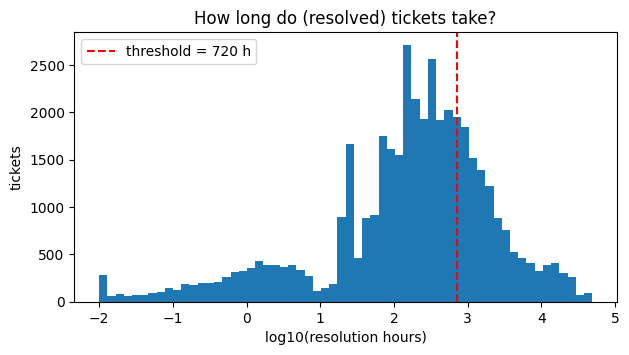

In [9]:
std, report = prepare_dataset(raw, mapping, RESOLUTION_TIME_THRESHOLD_HOURS, RESOLUTION_NUMERIC_UNIT)

print("TIMESTAMP COLUMNS USED")
print("  creation  :", mapping["created"])
print("  resolution:", mapping["resolved"])
print(f"\nactual_resolution_time = resolution - creation (hours)")
print(f"delayed = 1 if > {RESOLUTION_TIME_THRESHOLD_HOURS:g} h ({RESOLUTION_TIME_THRESHOLD_HOURS/24:.1f} days)\n")
for k, v in report.items():
    print(f"  {k:<62} {v:>12,}" if isinstance(v, int) else f"  {k:<62} {v:>12}")

modelling_rows = std[std["delayed"].notna()]
if len(modelling_rows) < 500:
    raise ValueError("Fewer than 500 usable tickets. Check the column mapping and the resolution column's unit.")
print("\nCLASS BALANCE (after creating the delayed label)")
print(modelling_rows["delayed"].value_counts().sort_index().to_string())
print(f"Delayed share (prevalence): {modelling_rows['delayed'].mean():.1%}")

yearly = (modelling_rows.assign(year=modelling_rows["created_ts"].dt.year)
          .groupby("year").agg(tickets=("delayed", "size"), delayed_share=("delayed", "mean")).round(3))
print("\nDelayed share by year of creation (drift check):")
display(yearly.T)

plt.figure(figsize=(7, 3.5))
plt.hist(np.log10(modelling_rows["resolution_hours"].dropna().clip(lower=0.01)), bins=60)
plt.axvline(np.log10(RESOLUTION_TIME_THRESHOLD_HOURS), color="red", linestyle="--",
            label=f"threshold = {RESOLUTION_TIME_THRESHOLD_HOURS:g} h")
plt.xlabel("log10(resolution hours)"); plt.ylabel("tickets"); plt.legend(); plt.title("How long do (resolved) tickets take?")
plt.show()

**Assumptions (read these!)**
1. The prediction moment is ticket creation; everything used as a feature must be known by then.
2. `issues.csv` has one row per ticket (`issues_snapshots.csv` repeats tickets per assignee and is not used).
3. **Not used on purpose:** assignee, contributor count, comment count, status, resolution, `started`/`ended`, all `wf_*`/`wfe_*` step columns, `processing_steps`, `last_change_date` — they are only known during or after the work.
4. Type/priority/project are assumed to be set when the ticket is opened (the data can't prove they weren't edited later).
5. "Still open" = no resolution date; the end of the data is the latest timestamp in the file.
6. Help-desk behaviour changes over 16 years, so recent history is weighted more and the split is chronological.

## 9. Build features and split the data

In [10]:
feat_df, NUMERIC, CATEGORICAL = engineer_features(std)
FEATURES = NUMERIC + CATEGORICAL
assert_leakage_safe(FEATURES)
print(f"{len(NUMERIC)} numeric features, categorical features: {CATEGORICAL}")
print("Leakage name-check passed.")
print("Time-safety check (old tickets' features unchanged when future tickets are removed):",
      history_is_time_safe(std.iloc[:15000]))

model_df = feat_df[feat_df["delayed"].notna()].reset_index(drop=True)
train_df, val_df, test_df, dropped = time_split(model_df, TRAIN_FRAC, VAL_FRAC, RESOLUTION_TIME_THRESHOLD_HOURS)
print(f"\nLabel embargo removed {dropped['train']} train and {dropped['validation']} validation tickets near the split dates.\n")
X_train, X_val, X_test = train_df[FEATURES], val_df[FEATURES], test_df[FEATURES]
y_train, y_val, y_test = (d["delayed"].astype(int) for d in (train_df, val_df, test_df))

for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:>10}: {len(d):>7,} tickets | {d['created_ts'].min().date()} -> {d['created_ts'].max().date()} "
          f"| delayed share = {d['delayed'].mean():.1%}")
    if d["delayed"].nunique() < 2:
        raise ValueError(f"The {name} split has only one class. Try another threshold.")
demo = build_preprocessor(NUMERIC, CATEGORICAL, scale=True).fit(X_train)
print("\nPreprocessed shape (train):", demo.transform(X_train).shape)

65 numeric features, categorical features: ['priority', 'category', 'project']
Leakage name-check passed.
Time-safety check (old tickets' features unchanged when future tickets are removed): True

Label embargo removed 666 train and 478 validation tickets near the split dates.

     train:  29,244 tickets | 2016-01-03 -> 2021-01-24 | delayed share = 30.7%
validation:   5,932 tickets | 2021-02-23 -> 2022-03-06 | delayed share = 26.5%
      test:   6,410 tickets | 2022-04-05 -> 2023-03-14 | delayed share = 19.9%

Preprocessed shape (train): (29244, 291)


## 10. Metrics, decision threshold and the models

* **PR-AUC** is the main metric; **ROC-AUC** shows ranking quality independent of class balance; **Brier** measures probability honesty.
* The **decision threshold** is picked on validation to match the operational goal in Config.
* Models: majority-class baseline, Logistic Regression, Random Forest, XGBoost (with **early stopping**). Each is tuned on validation PR-AUC, including a **recency-weighting** choice for training tickets.

In [23]:
def compute_metrics(y_true, proba, threshold: float) -> Dict[str, float]:
    """All requested metrics at a given decision threshold."""
    y_true = np.asarray(y_true)
    pred = (np.asarray(proba) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {"threshold": float(threshold),
            "precision": precision_score(y_true, pred, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0),
            "pr_auc": average_precision_score(y_true, proba),
            "roc_auc": roc_auc_score(y_true, proba),
            "brier": brier_score_loss(y_true, proba),
            "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


def select_threshold(y_true, proba, goal: str = OPERATIONAL_GOAL, target_recall: float = TARGET_RECALL,
                     target_precision: float = TARGET_PRECISION) -> float:
    """Pick the decision threshold on VALIDATION data.

    high_recall   : highest threshold that still catches >= target_recall of delayed tickets
    high_precision: best recall while precision >= target_precision
    f1 / fallback : best F1
    """
    prec, rec, thr = precision_recall_curve(y_true, proba)
    prec, rec = prec[:-1], rec[:-1]
    if len(thr) == 0:
        return 0.5
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    if goal == "high_recall" and (rec >= target_recall).any():
        ok = np.where(rec >= target_recall)[0]
        return float(thr[ok[np.argmax(prec[ok])]])
    if goal == "high_precision" and (prec >= target_precision).any():
        ok = np.where(prec >= target_precision)[0]
        return float(thr[ok[np.argmax(rec[ok])]])
    return float(thr[np.argmax(f1)])


def make_grid(d: Dict[str, list]) -> List[Dict[str, Any]]:
    return [dict(zip(d, vals)) for vals in itertools.product(*d.values())]


def make_xgb(n_estimators: int, early: bool, max_depth: int, learning_rate: float,
             min_child_weight: float, scale_pos_weight: float):
    kw = dict(early_stopping_rounds=50, eval_metric="aucpr") if early else dict(eval_metric="logloss")
    return XGBClassifier(n_estimators=n_estimators, max_depth=max_depth, learning_rate=learning_rate,
                         min_child_weight=min_child_weight, scale_pos_weight=scale_pos_weight, subsample=0.8,
                         colsample_bytree=0.8, reg_lambda=5.0, tree_method="hist", n_jobs=-1,
                         random_state=RANDOM_STATE, **kw)


def fit_generic(spec, params, Xtr, ytr, Xva, yva, w):
    """Plain scikit-learn style fit (optionally with recency weights)."""
    pipe = Pipeline([("prep", build_preprocessor(NUMERIC, CATEGORICAL, spec["scale"])),
                     ("clf", spec["build"](**params))])
    pipe.fit(Xtr, ytr, **({"clf__sample_weight": w} if w is not None else {}))
    return pipe


def fit_xgb_early_stop(spec, params, Xtr, ytr, Xva, yva, w):
    """XGBoost that stops adding trees when validation PR-AUC stops improving."""
    prep = build_preprocessor(NUMERIC, CATEGORICAL, False).fit(Xtr)
    clf = spec["build"](**params)
    clf.fit(prep.transform(Xtr), ytr, sample_weight=w, eval_set=[(prep.transform(Xva), yva)], verbose=False)
    return Pipeline([("prep", prep), ("clf", clf)])


def build_model_specs(pos_weight: float) -> Dict[str, Dict[str, Any]]:
    """Each model: needs scaling?, settings to try, how to build, how to fit."""
    fast = FAST_MODE
    specs: Dict[str, Dict[str, Any]] = {
        "baseline_majority": {"scale": False, "weights": False, "grid": [{}], "fit": fit_generic,
                              "build": lambda: DummyClassifier(strategy="prior")},
        "logistic_regression": {"scale": True, "weights": True, "fit": fit_generic,
                                "grid": make_grid({"C": [0.01, 0.1, 1.0] if not fast else [0.1]}),
                                "build": lambda C: LogisticRegression(C=C, class_weight="balanced", max_iter=2000,
                                                                       random_state=RANDOM_STATE)},
        "random_forest": {"scale": False, "weights": True, "fit": fit_generic,
                          "grid": make_grid({"max_depth": [8, 14] if not fast else [10], "min_samples_leaf": [10, 40] if not fast else [20]}),
                          "build": lambda max_depth, min_samples_leaf: RandomForestClassifier(
                              n_estimators=200 if not fast else 60, max_depth=max_depth, min_samples_leaf=min_samples_leaf,
                              class_weight="balanced_subsample", n_jobs=-1, random_state=RANDOM_STATE)},
    }
    if HAS_XGB:
        spw = sorted({1.0, round(pos_weight, 2)})
        specs["xgboost"] = {
            "scale": False, "weights": True, "fit": fit_xgb_early_stop, "refit_fixed": True,
            "grid": make_grid({"max_depth": [4, 6] if not fast else [4], "learning_rate": [0.05], "min_child_weight": [10],
                               "scale_pos_weight": spw if not fast else [1.0]}),
            "build": lambda max_depth, learning_rate, min_child_weight, scale_pos_weight: make_xgb(
                1500, True, max_depth, learning_rate, min_child_weight, scale_pos_weight),
            "build_fixed": lambda n, max_depth, learning_rate, min_child_weight, scale_pos_weight: make_xgb(
                n, False, max_depth, learning_rate, min_child_weight, scale_pos_weight)}
    elif HAS_LGBM:
        specs["lightgbm"] = {"scale": False, "weights": True, "fit": fit_generic,
                             "grid": make_grid({"max_depth": [4, 6], "learning_rate": [0.05]}),
                             "build": lambda max_depth, learning_rate: LGBMClassifier(
                                 n_estimators=400, max_depth=max_depth, learning_rate=learning_rate,
                                 random_state=RANDOM_STATE, verbose=-1)}
    else:
        specs["hist_gradient_boosting"] = {"scale": False, "weights": True, "fit": fit_generic,
                                           "grid": make_grid({"max_depth": [4, 6], "learning_rate": [0.05]}),
                                           "build": lambda max_depth, learning_rate: HistGradientBoostingClassifier(
                                               max_depth=max_depth, learning_rate=learning_rate, random_state=RANDOM_STATE)}
    return specs


def fit_and_tune(spec, Xtr, ytr, Xva, yva, created_train) -> Tuple[Pipeline, Dict[str, Any], float]:
    """Try each setting (and each recency half-life) on TRAIN; keep the best VALIDATION PR-AUC."""
    best = (None, {}, -1.0)
    half_lives = HALF_LIFE_CHOICES_DAYS if spec.get("weights") else [None]
    if FAST_MODE:
        half_lives = half_lives[:1]
    for hl in half_lives:
        w = recency_weights(created_train, hl)
        for params in spec["grid"]:
            pipe = spec["fit"](spec, params, Xtr, ytr, Xva, yva, w)
            score = average_precision_score(yva, pipe.predict_proba(Xva)[:, 1])
            if score > best[2]:
                best = (pipe, {**params, "half_life_days": hl}, score)
    pipe, params, score = best
    if spec.get("refit_fixed"):                      # rebuild with exactly the best number of trees (clean model for SHAP)
        n_trees = int(pipe.named_steps["clf"].best_iteration) + 1
        p = {k: v for k, v in params.items() if k != "half_life_days"}
        w = recency_weights(created_train, params["half_life_days"])
        prep = pipe.named_steps["prep"]
        clf = spec["build_fixed"](n_trees, **p).fit(prep.transform(Xtr), ytr, sample_weight=w)
        pipe, params = Pipeline([("prep", prep), ("clf", clf)]), {**params, "n_trees": n_trees}
    return pipe, params, score


pos_weight = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))
print(f"Train class ratio: {pos_weight:.2f} on-time per delayed ticket")
MODEL_SPECS = build_model_specs(pos_weight)
fitted: Dict[str, Pipeline] = {}
best_params: Dict[str, Dict[str, Any]] = {}
for name, spec in MODEL_SPECS.items():
    logger.info("Training %s (%d setting(s) x recency options)...", name, len(spec["grid"]))
    fitted[name], best_params[name], score = fit_and_tune(spec, X_train, y_train, X_val, y_val, train_df["created_ts"])
    logger.info("   best validation PR-AUC = %.4f with %s", score, best_params[name])

2026-10-28 13:35:51,759 | INFO | Training baseline_majority (1 setting(s) x recency options)...


Train class ratio: 2.26 on-time per delayed ticket


2026-10-28 13:35:52,139 | INFO |    best validation PR-AUC = 0.2647 with {'half_life_days': None}
2026-10-28 13:35:52,140 | INFO | Training logistic_regression (3 setting(s) x recency options)...
2026-10-28 13:36:11,842 | INFO |    best validation PR-AUC = 0.4995 with {'C': 0.1, 'half_life_days': 1095}
2026-10-28 13:36:11,845 | INFO | Training random_forest (4 setting(s) x recency options)...
2026-10-28 13:37:33,280 | INFO |    best validation PR-AUC = 0.5419 with {'max_depth': 4, 'learning_rate': 0.05, 'min_child_weight': 10, 'scale_pos_weight': 1.0, 'half_life_days': None, 'n_trees': 249}


## 11. Compare models on the validation set

In [ ]:
thresholds: Dict[str, float] = {}
val_rows = {}
for name, pipe in fitted.items():
    p_val = pipe.predict_proba(X_val)[:, 1]
    thresholds[name] = 0.5 if name.startswith("baseline") else select_threshold(y_val, p_val)
    val_rows[name] = compute_metrics(y_val, p_val, thresholds[name])

COLS = ["threshold", "precision", "recall", "f1", "pr_auc", "roc_auc", "brier", "tn", "fp", "fn", "tp"]
val_table = pd.DataFrame(val_rows).T[COLS]
print(f"Validation delayed share (= PR-AUC of random guessing): {y_val.mean():.3f}")
display(val_table.round(4))

candidates = [n for n in fitted if not n.startswith("baseline")]
best_name = max(candidates, key=lambda n: val_table.loc[n, "pr_auc"])
print(f"\nBest model by VALIDATION PR-AUC: {best_name}  (settings: {best_params[best_name]})")

## 
12. Probability calibration (validation data only)

A "0.80 risk" should mean ~80 % of such tickets are really delayed. We compare no calibration vs. Platt (sigmoid) vs. isotonic: fitted on the first half of validation, scored (Brier) on the second half; the winner is refitted on all of validation. The test set is not touched.

In [24]:
def _make_calibrator(fitted_pipe: Pipeline, method: str):
    """Calibrator wrapping an already-trained pipeline (works across scikit-learn versions)."""
    try:
        from sklearn.frozen import FrozenEstimator
        return CalibratedClassifierCV(FrozenEstimator(fitted_pipe), method=method)
    except ImportError:
        return CalibratedClassifierCV(fitted_pipe, method=method, cv="prefit")


def calibrate_on_validation(pipe: Pipeline, Xva: pd.DataFrame, yva: pd.Series) -> Tuple[Any, str, Dict[str, float]]:
    """Pick none/sigmoid/isotonic using only validation data."""
    half = len(Xva) // 2
    Xa, ya, Xb, yb = Xva.iloc[:half], yva.iloc[:half], Xva.iloc[half:], yva.iloc[half:]
    scores = {"none": float(brier_score_loss(yb, pipe.predict_proba(Xb)[:, 1]))}
    for method in ("sigmoid", "isotonic"):
        try:
            cal = _make_calibrator(pipe, method).fit(Xa, ya)
            scores[method] = float(brier_score_loss(yb, cal.predict_proba(Xb)[:, 1]))
        except Exception as exc:
            logger.warning("Calibration '%s' failed: %s", method, exc)
    choice = min(scores, key=scores.get)
    if choice == "none":
        return pipe, "none", scores
    return _make_calibrator(pipe, choice).fit(Xva, yva), choice, scores


base_pipe = fitted[best_name]
final_model, calib_method, calib_scores = calibrate_on_validation(base_pipe, X_val, y_val)
print("Brier on 2nd half of validation (lower = better):", {k: round(v, 5) for k, v in calib_scores.items()})
print("Calibration chosen:", calib_method)

p_val_final = final_model.predict_proba(X_val)[:, 1]
THRESHOLD = select_threshold(y_val, p_val_final)
print(f"\nGoal = {OPERATIONAL_GOAL} -> decision threshold = {THRESHOLD:.4f}")
print({k: round(float(v), 4) for k, v in compute_metrics(y_val, p_val_final, THRESHOLD).items() if k in ("precision", "recall", "f1", "pr_auc", "brier")})

Brier on 2nd half of validation (lower = better): {'none': 0.17531, 'sigmoid': 0.16462, 'isotonic': 0.16487}
Calibration chosen: sigmoid

Goal = high_recall -> decision threshold = 0.1842
{'precision': 0.345, 'recall': 0.8006, 'f1': 0.4822, 'pr_auc': 0.5472, 'brier': 0.1643}


## 13. Final test-set evaluation (run once)

First and only time the test set is scored. Nothing above used it for any decision.

Test delayed share (= PR-AUC of random guessing): 0.199


,threshold,precision,recall,f1,pr_auc,roc_auc,brier,tn,fp,fn,tp
baseline_majority,0.5000,0.0000,0.0000,0.0000,0.1989,0.5000,0.1711,5135.0,0.0,1275.0,0.0
logistic_regression,0.2009,0.2782,0.6863,0.3959,0.3986,0.6845,0.1514,2865.0,2270.0,400.0,875.0
random_forest,0.3130,0.2786,0.7890,0.4118,0.4935,0.7416,0.1587,2530.0,2605.0,269.0,1006.0
xgboost,0.1412,0.3004,0.7984,0.4365,0.5004,0.7608,0.1315,2764.0,2371.0,257.0,1018.0
FINAL: random_forest + sigmoid calibration,0.1842,0.2786,0.7890,0.4118,0.4935,0.7416,0.1352,2530.0,2605.0,269.0,1006.0



Confusion matrix, final model (rows = actual, columns = predicted):


,pred on-time,pred delayed
actual on-time,2530,2605
actual delayed,269,1006


Classification report, final model:
              precision    recall  f1-score   support

     on-time       0.90      0.49      0.64      5135
     delayed       0.28      0.79      0.41      1275

    accuracy                           0.55      6410
   macro avg       0.59      0.64      0.52      6410
weighted avg       0.78      0.55      0.59      6410

Top 10% highest-risk tickets: 60.1% are really delayed (vs 19.9% overall -> 3.02x lift)
Top 20% highest-risk tickets: 47.0% are really delayed (vs 19.9% overall -> 2.36x lift)

PLAIN-ENGLISH VERDICT
  ROC-AUC 0.742 (0.5 = coin flip) | PR-AUC 0.493 vs 0.199 for guessing
  -> Modest signal: helpful for prioritising, not for hard decisions.


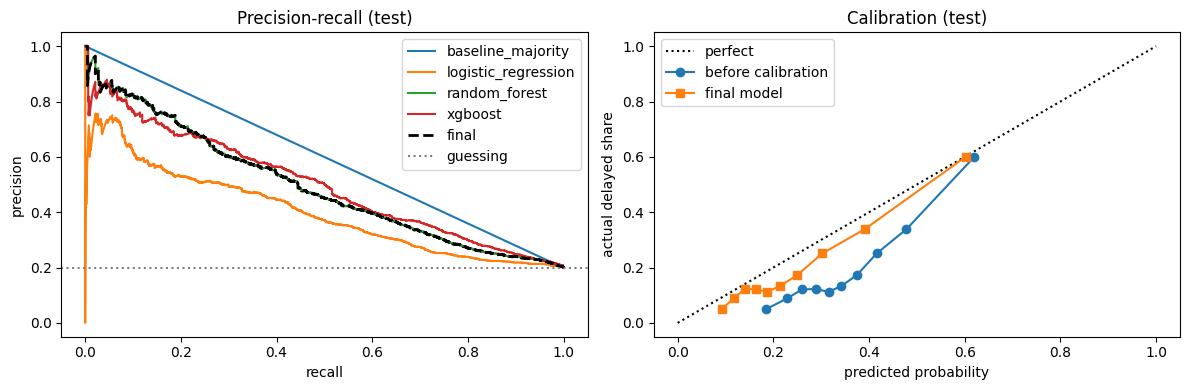

Calibration curve data (final model, test):


,mean_predicted,actual_fraction_delayed
0,0.092,0.050
1,0.118,0.089
2,0.140,0.122
3,0.163,0.122
4,0.187,0.112
5,0.213,0.133
6,0.249,0.172
7,0.302,0.251
8,0.391,0.339
9,0.602,0.601


In [25]:
def risk_category(p: float, low: float = RISK_LOW_BELOW, high: float = RISK_HIGH_FROM) -> str:
    """low: p < 0.4 | medium: 0.4 <= p < 0.7 | high: p >= 0.7"""
    return "low" if p < low else ("medium" if p < high else "high")


test_rows = {}
for name, pipe in fitted.items():
    test_rows[name] = compute_metrics(y_test, pipe.predict_proba(X_test)[:, 1], thresholds[name])
final_label = f"FINAL: {best_name} + {calib_method} calibration"
p_test_final = final_model.predict_proba(X_test)[:, 1]
test_rows[final_label] = compute_metrics(y_test, p_test_final, THRESHOLD)
val_rows_final = compute_metrics(y_val, p_val_final, THRESHOLD)

test_table = pd.DataFrame(test_rows).T[COLS]
print(f"Test delayed share (= PR-AUC of random guessing): {y_test.mean():.3f}")
display(test_table.round(4))

print("\nConfusion matrix, final model (rows = actual, columns = predicted):")
display(pd.DataFrame(confusion_matrix(y_test, (p_test_final >= THRESHOLD).astype(int), labels=[0, 1]),
                     index=["actual on-time", "actual delayed"], columns=["pred on-time", "pred delayed"]))
print("Classification report, final model:")
print(classification_report(y_test, (p_test_final >= THRESHOLD).astype(int), target_names=["on-time", "delayed"], zero_division=0))

# Operational view: how good is the model at ranking tickets for triage?
order_ = np.argsort(-p_test_final)
for frac in (0.1, 0.2):
    top = order_[: int(len(order_) * frac)]
    print(f"Top {int(frac*100)}% highest-risk tickets: {y_test.to_numpy()[top].mean():.1%} are really delayed "
          f"(vs {y_test.mean():.1%} overall -> {y_test.to_numpy()[top].mean() / y_test.mean():.2f}x lift)")

t_ = test_rows[final_label]
print("\nPLAIN-ENGLISH VERDICT")
print(f"  ROC-AUC {t_['roc_auc']:.3f} (0.5 = coin flip) | PR-AUC {t_['pr_auc']:.3f} vs {y_test.mean():.3f} for guessing")
if t_["roc_auc"] >= 0.75:
    print("  -> Useful ranking signal.")
elif t_["roc_auc"] >= 0.65:
    print("  -> Modest signal: helpful for prioritising, not for hard decisions.")
else:
    print("  -> Weak signal: delay is mostly driven by things unknown at creation. Try another threshold/target (Config).")

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for name, pipe in fitted.items():
    pr, rc, _ = precision_recall_curve(y_test, pipe.predict_proba(X_test)[:, 1])
    ax[0].plot(rc, pr, label=name)
pr, rc, _ = precision_recall_curve(y_test, p_test_final)
ax[0].plot(rc, pr, "k--", linewidth=2, label="final")
ax[0].axhline(y_test.mean(), color="gray", linestyle=":", label="guessing")
ax[0].set_xlabel("recall"); ax[0].set_ylabel("precision"); ax[0].set_title("Precision-recall (test)"); ax[0].legend()

frac_pos, mean_pred = calibration_curve(y_test, p_test_final, n_bins=10, strategy="quantile")
frac_pos_u, mean_pred_u = calibration_curve(y_test, base_pipe.predict_proba(X_test)[:, 1], n_bins=10, strategy="quantile")
ax[1].plot([0, 1], [0, 1], "k:", label="perfect")
ax[1].plot(mean_pred_u, frac_pos_u, "o-", label="before calibration")
ax[1].plot(mean_pred, frac_pos, "s-", label="final model")
ax[1].set_xlabel("predicted probability"); ax[1].set_ylabel("actual delayed share"); ax[1].set_title("Calibration (test)"); ax[1].legend()
plt.tight_layout(); plt.show()
print("Calibration curve data (final model, test):")
display(pd.DataFrame({"mean_predicted": mean_pred, "actual_fraction_delayed": frac_pos}).round(3))

## 14. Explainability

* **Global importance:** permutation importance (shuffle one input at a time; how much does validation PR-AUC drop?).
* **Per-ticket:** SHAP (if installed) shows how much each input pushed *this* ticket's score up or down; one-hot columns are summed back to the original field. Fallback: "what if this field had a typical value?".

The output keeps apart **model-estimated risk** (`risk_probability`), **known ticket information** (`value`) and **contributing factors** (`impact`; positive = pushes risk up, in the raw model's score units).

GLOBAL FEATURE IMPORTANCE (drop in validation PR-AUC when shuffled)


,importance
reporter_delay_rate,0.00579
project_category_delay_rate,0.00494
category_recent_n,0.00483
project_priority_delay_rate,0.00406
category_recent_rate,0.00240
category_prior_n,0.00237
category_gap_hrs,0.00227
priority_gap_hrs,0.00185
project_delay_rate,0.00168
project_open_now,0.00152


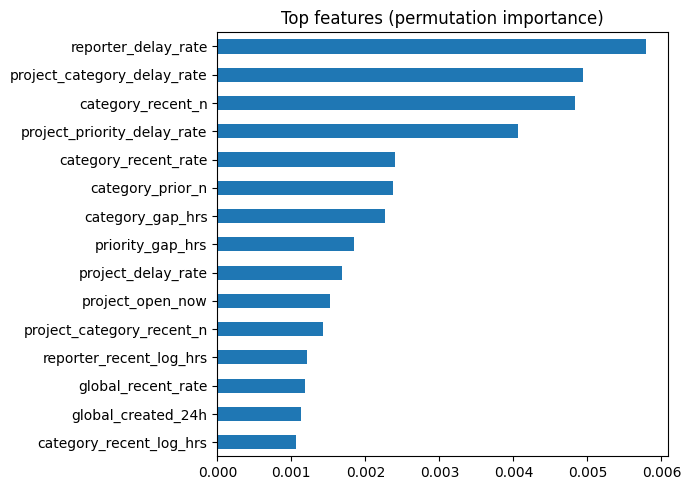

In [27]:
TREE_MODELS = {"RandomForestClassifier", "XGBClassifier", "LGBMClassifier"}


def original_feature(transformed_name: str, cat_cols: List[str]) -> str:
    """'cat__priority_high' -> 'priority' | 'num__created_hour' -> 'created_hour'"""
    prefix, base = transformed_name.split("__", 1)
    if prefix == "cat":
        for c in sorted(cat_cols, key=len, reverse=True):
            if base == c or base.startswith(c + "_"):
                return c
    return base


def explain_rows(base_pipeline: Pipeline, X: pd.DataFrame, reference: Dict[str, Any],
                 background: pd.DataFrame) -> pd.DataFrame:
    """Per-ticket impact of each ORIGINAL feature (rows = tickets, columns = features)."""
    prep, clf = base_pipeline.named_steps["prep"], base_pipeline.named_steps["clf"]
    cat_cols = list(prep.transformers_[1][2])
    kind = type(clf).__name__
    if HAS_SHAP and (kind in TREE_MODELS or kind == "LogisticRegression"):
        try:
            names = prep.get_feature_names_out()
            Xt = prep.transform(X)
            if kind in TREE_MODELS:
                sv = shap.TreeExplainer(clf).shap_values(Xt, check_additivity=False)
            else:
                sv = shap.LinearExplainer(clf, prep.transform(background)).shap_values(Xt)
            if isinstance(sv, list):
                sv = sv[1]
            sv = np.asarray(sv)
            if sv.ndim == 3:
                sv = sv[:, :, 1]
            frame = pd.DataFrame(sv, columns=names, index=X.index)
            return frame.T.groupby([original_feature(n, cat_cols) for n in names]).sum().T
        except Exception as exc:
            logger.warning("SHAP failed (%s). Falling back to the 'what-if typical value' method.", exc)
    base_p = base_pipeline.predict_proba(X)[:, 1]
    out = {}
    for col in X.columns:
        X_alt = X.copy()
        X_alt[col] = reference[col]
        out[col] = base_p - base_pipeline.predict_proba(X_alt)[:, 1]
    return pd.DataFrame(out, index=X.index)


def _py(v: Any) -> Any:
    """Make numpy values JSON-friendly."""
    v = v.item() if hasattr(v, "item") else v
    return round(v, 4) if isinstance(v, float) else v


def score_feature_rows(bundle: Dict[str, Any], rows: pd.DataFrame, top_k: int = 5) -> List[Dict[str, Any]]:
    """Risk score + explanation for rows that already contain the engineered features."""
    X = rows[bundle["feature_columns"]]
    proba = bundle["model"].predict_proba(X)[:, 1]
    impacts = explain_rows(bundle["base_pipeline"], X, bundle["reference"], bundle["background"])
    results = []
    for i, p in enumerate(proba):
        imp = impacts.iloc[i]
        top = imp.abs().sort_values(ascending=False).head(top_k).index
        results.append({
            "ticket_id": str(rows.iloc[i]["ticket_id"]),
            "risk_probability": round(float(p), 4),
            "risk_category": risk_category(float(p)),
            "predicted_delayed": bool(p >= bundle["threshold"]),
            "threshold_used": round(float(bundle["threshold"]), 4),
            "top_factors": [{"feature": f, "value": _py(X.iloc[i][f]), "impact": round(float(imp[f]), 4)} for f in top],
            "model_version": bundle["model_version"],
        })
    return results


sample = X_val.sample(min(3000, len(X_val)), random_state=RANDOM_STATE)
perm = permutation_importance(base_pipe, sample, y_val.loc[sample.index], scoring="average_precision",
                              n_repeats=5, random_state=RANDOM_STATE, n_jobs=1)
importance = pd.Series(perm.importances_mean, index=FEATURES).sort_values(ascending=False)
print("GLOBAL FEATURE IMPORTANCE (drop in validation PR-AUC when shuffled)")
display(importance.round(5).to_frame("importance").head(15))
importance.head(15).iloc[::-1].plot.barh(figsize=(7, 5), title="Top features (permutation importance)")
plt.tight_layout(); plt.show()

reference = {c: X_train[c].median() for c in NUMERIC}
reference.update({c: X_train[c].mode().iloc[0] for c in CATEGORICAL})
background = X_train.sample(min(200, len(X_train)), random_state=RANDOM_STATE)

## 15. Save the model, threshold, metadata and history

Saved to `/kaggle/working/artifacts` (Output tab): `delay_risk_model.joblib` (preprocessing + model + threshold), `delay_risk_metadata.json`, `history_reference.csv.gz` (past tickets needed to compute history features for new tickets), `MODEL_CARD.md`.

In [28]:
def make_bundle(final_model, base_pipeline, threshold, numeric, categorical, mapping, reference, background) -> Dict[str, Any]:
    """Everything needed to score new tickets, in one picklable dictionary."""
    return {"model": final_model, "base_pipeline": base_pipeline, "threshold": float(threshold),
            "feature_columns": list(numeric) + list(categorical), "numeric_features": list(numeric),
            "categorical_features": list(categorical), "mapping": mapping, "reference": reference,
            "background": background, "model_version": MODEL_VERSION,
            "risk_bins": {"low_below": RISK_LOW_BELOW, "high_from": RISK_HIGH_FROM},
            "threshold_hours": RESOLUTION_TIME_THRESHOLD_HOURS, "numeric_unit": RESOLUTION_NUMERIC_UNIT}


bundle = make_bundle(final_model, base_pipe, THRESHOLD, NUMERIC, CATEGORICAL, mapping, reference, background)
joblib.dump(bundle, ARTIFACT_DIR / "delay_risk_model.joblib")

hist_cols = ["ticket_id", "created_ts", "resolved_ts", "known_ts", "delayed"] + [c for c in ["priority", "category", "project", "reporter"] if c in std.columns]
std[hist_cols].to_csv(ARTIFACT_DIR / "history_reference.csv.gz", index=False)

metadata = {
    "model_version": MODEL_VERSION,
    "training_date_utc": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "target": f"delayed = 1 if resolution time > {RESOLUTION_TIME_THRESHOLD_HOURS:g} hours (open tickets older than that are delayed)",
    "resolution_time_threshold_hours": RESOLUTION_TIME_THRESHOLD_HOURS,
    "threshold_mode": THRESHOLD_MODE,
    "threshold_sweep_validation": sweep.round(4).to_dict(orient="records") if len(sweep) else [],
    "column_mapping": mapping,
    "selected_model": best_name, "selected_model_params": best_params[best_name],
    "calibration": calib_method, "operational_goal": OPERATIONAL_GOAL,
    "decision_threshold": THRESHOLD,
    "risk_categories": {"low": f"p < {RISK_LOW_BELOW}", "medium": f"{RISK_LOW_BELOW} <= p < {RISK_HIGH_FROM}", "high": f"p >= {RISK_HIGH_FROM}"},
    "feature_names": {"numeric": NUMERIC, "categorical": CATEGORICAL},
    "split": {n: {"rows": len(d), "from": str(d["created_ts"].min()), "to": str(d["created_ts"].max()),
                  "delayed_share": float(d["delayed"].mean())} for n, d in [("train", train_df), ("validation", val_df), ("test", test_df)]},
    "label_embargo_rows_removed": dropped,
    "rows_excluded_report": report,
    "metrics": {"validation": val_rows_final, "test": test_rows[final_label],
                "all_models_validation": val_rows, "all_models_test": test_rows},
    "random_state": RANDOM_STATE,
}
(ARTIFACT_DIR / "delay_risk_metadata.json").write_text(json.dumps(metadata, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("Saved:", sorted(p.name for p in ARTIFACT_DIR.iterdir()))

Saved: ['MODEL_CARD.md', 'delay_risk_metadata.json', 'delay_risk_model.joblib', 'history_reference.csv.gz']


## 16. Predict for new tickets (and demo on real test tickets)

`score_new_tickets` takes **raw ticket rows** (same columns as `issues.csv`). Resolution information in them is discarded, history features are computed from the saved history, and you get the JSON-style output.

In [29]:
def score_new_tickets(bundle: Dict[str, Any], new_raw: pd.DataFrame, history_ref: pd.DataFrame, top_k: int = 5) -> List[Dict[str, Any]]:
    """Score brand-new tickets. new_raw has the same columns as the original issues file."""
    mp = bundle["mapping"]
    need = [mp[k] for k in ("created", "priority", "category", "project", "reporter") if mp.get(k)]
    missing = [c for c in need if c not in new_raw.columns]
    if missing:
        raise ValueError(f"New tickets are missing required columns: {missing}")
    raw_new = new_raw.copy()
    raw_new[mp["resolved"]] = np.nan                       # never use resolution info for a new ticket
    new_std = standardize(raw_new, mp, bundle["threshold_hours"], bundle["numeric_unit"])
    if new_std["created_ts"].isna().any():
        raise ValueError("Some new tickets have an unreadable creation time.")
    new_std["_is_new"] = True
    hist = history_ref.copy()
    for c in ("created_ts", "resolved_ts", "known_ts"):
        hist[c] = parse_dt(hist[c])
    hist["_is_new"] = False
    combined = pd.concat([hist, new_std], ignore_index=True)
    feats, _, _ = engineer_features(combined)
    return score_feature_rows(bundle, feats[feats["_is_new"] == True], top_k=top_k)


loaded = joblib.load(ARTIFACT_DIR / "delay_risk_model.joblib")
order = np.argsort(-p_test_final)
demo_rows = test_df.iloc[[order[0], order[len(order) // 2], order[-1]]]       # highest, middle, lowest risk
examples = score_feature_rows(loaded, demo_rows)
print("Three example tickets from the TEST set (highest, middle, lowest model risk):\n")
print(json.dumps(examples, indent=2, default=str))
print("\nACTUAL outcome of those tickets (unknown at prediction time):", demo_rows["delayed"].astype(int).tolist())

Three example tickets from the TEST set (highest, middle, lowest model risk):

[
  {
    "ticket_id": "1006044",
    "risk_probability": 0.8956,
    "risk_category": "high",
    "predicted_delayed": true,
    "threshold_used": 0.1842,
    "top_factors": [
      {
        "feature": "project_category_recent_rate",
        "value": 0.7631,
        "impact": 0.0508
      },
      {
        "feature": "project_recent_rate",
        "value": 0.8612,
        "impact": 0.0397
      },
      {
        "feature": "project_category_open_now",
        "value": 96.0,
        "impact": 0.0353
      },
      {
        "feature": "category_recent_rate",
        "value": 0.7733,
        "impact": 0.0342
      },
      {
        "feature": "project_category_delay_rate",
        "value": 0.7103,
        "impact": 0.0317
      }
    ],
    "model_version": "delay-risk-v3"
  },
  {
    "ticket_id": "1007740",
    "risk_probability": 0.1989,
    "risk_category": "low",
    "predicted_delayed": true,
    "t

## 17. Auto-generate the model card from the real run

In [30]:
t, v = test_rows[final_label], val_rows_final
excluded = {k: v_ for k, v_ in report.items() if k.startswith(("excluded", "exact", "open"))}
card = f"""# Model Card — Ticket Delay Risk ({MODEL_VERSION})

**Target.** `delayed = 1` if resolution time (resolution timestamp − creation timestamp) > {RESOLUTION_TIME_THRESHOLD_HOURS:g} hours
({RESOLUTION_TIME_THRESHOLD_HOURS/24:.1f} days; threshold mode: {THRESHOLD_MODE}). Tickets still open and older than the threshold at the end of the data count as delayed.
Prediction time = ticket creation. Delayed share overall: {modelling_rows['delayed'].mean():.1%}.

**Data.** Help Desk Tickets (Mendeley Data, DOI 10.17632/btm76zndnt.3, CC BY 4.0), file `{ISSUES_FILE}`.
Rows used: {report['ROWS USED FOR MODELLING']:,}. Exclusions: {excluded}.

**Features (all known at ticket creation).** {', '.join(CATEGORICAL)}; calendar features; time-safe history features per
everyone/category/project/priority/reporter/project×category (past delay rate, last-{RECENT_WINDOW_DAYS}-day delay rate, open tickets, arrivals in the last 24 h / 7 days).
**Not used:** assignee, status, resolution, comment/contributor counts, started/ended, workflow-step times, processing steps.

**Split.** Chronological 70/15/15 with a label embargo. Train {len(train_df):,} | Validation {len(val_df):,} | Test {len(test_df):,}. Test period starts {test_df['created_ts'].min().date()}.
Delayed share: train {y_train.mean():.1%}, validation {y_val.mean():.1%}, test {y_test.mean():.1%}.

**Model.** {best_name} ({best_params[best_name]}), calibration: {calib_method}.
**Decision threshold:** {THRESHOLD:.3f} (goal: {OPERATIONAL_GOAL}, chosen on validation). Risk bands: low < {RISK_LOW_BELOW}, medium < {RISK_HIGH_FROM}, high ≥ {RISK_HIGH_FROM}.

**Metrics (test, this run).** PR-AUC {t['pr_auc']:.3f} (guessing = {y_test.mean():.3f}) | ROC-AUC {t['roc_auc']:.3f} | precision {t['precision']:.3f} | recall {t['recall']:.3f} | F1 {t['f1']:.3f} | Brier {t['brier']:.4f}
(validation PR-AUC {v['pr_auc']:.3f}).

**Limitations.** One company's help desk, 2007–2023; processes and staffing change. Fields are masked/anonymised.
Type/priority may be edited after creation (not verifiable). Assignee-at-creation is not modelled. Delay is defined only by the threshold rule,
which for this data was {'chosen automatically from validation results' if THRESHOLD_MODE == 'auto' else 'set manually'}; a business SLA may differ.
Probabilities are calibrated on one validation window and can drift.

**Responsible use.** Use scores to *prioritise attention* (triage), not to judge or penalise agents or reporters. Keep a human in the loop,
monitor precision/recall and calibration on new data, and retrain when the process changes.
"""
(ARTIFACT_DIR / "MODEL_CARD.md").write_text(card)
print(card)

# Model Card — Ticket Delay Risk (delay-risk-v3)

**Target.** `delayed = 1` if resolution time (resolution timestamp − creation timestamp) > 720 hours
(30.0 days; threshold mode: auto). Tickets still open and older than the threshold at the end of the data count as delayed.
Prediction time = ticket creation. Delayed share overall: 28.4%.

**Data.** Help Desk Tickets (Mendeley Data, DOI 10.17632/btm76zndnt.3, CC BY 4.0), file `issues.csv`.
Rows used: 42,730. Exclusions: {'exact_duplicates_removed': 0, 'excluded: missing/invalid creation time': 0, 'excluded: negative resolution time': 0, 'open tickets already past threshold -> labelled delayed': 609, 'excluded: open tickets younger than threshold (unknown yet)': 244}.

**Features (all known at ticket creation).** priority, category, project; calendar features; time-safe history features per
everyone/category/project/priority/reporter/project×category (past delay rate, last-90-day delay rate, open tickets, arrivals in the last 24 h / 7 da

## 18. Self-tests (pytest-style checks, run right here)

They use a small **synthetic** dataset so they finish in seconds and don't depend on your real data.

In [31]:
import tempfile

SYN_MAP = {"ticket_id": "issue_id", "created": "created_at", "resolved": "resolved_at", "priority": "priority",
           "category": "category", "project": "project", "reporter": "reporter", "country": None, "text": "summary"}


def make_synthetic_tickets(n: int = 800, seed: int = 42) -> pd.DataFrame:
    """Fake tickets where high priority tickets tend to take longer."""
    rng = np.random.default_rng(seed)
    created = pd.Timestamp("2020-01-01") + pd.to_timedelta(np.sort(rng.uniform(0, 365 * 24, n)), unit="h")
    priority = rng.choice(["low", "medium", "high"], n, p=[0.3, 0.5, 0.2])
    base = pd.Series(priority).map({"low": 20, "medium": 40, "high": 70}).to_numpy()
    hours = rng.gamma(2.0, base / 2.0)
    return pd.DataFrame({"issue_id": [f"TCK-{i}" for i in range(n)], "created_at": created,
                         "resolved_at": created + pd.to_timedelta(hours, unit="h"), "priority": priority,
                         "category": rng.choice(["bug", "access", "feature"], n), "project": rng.choice(["A", "B"], n),
                         "reporter": rng.choice([f"user{i}" for i in range(8)], n),
                         "summary": ["please help with the login problem"] * n})


def _frame(created, resolved):
    return pd.DataFrame({"issue_id": list("abcdefg")[:len(created)], "created_at": created, "resolved_at": resolved,
                         "priority": "x", "category": "x", "project": "x", "reporter": "x", "summary": "t"})


def test_target_creation_and_open_ticket_rule():
    d0 = pd.Timestamp("2021-01-01")
    h = lambda x: d0 + pd.Timedelta(hours=x)
    # a: 47h  b: exactly 48h  c: 49h  d: negative  e: open & old (>48h at data end)  f: open & young (<48h)
    df = _frame([d0] * 4 + [d0, h(300)], [h(47), h(48), h(49), h(-5), pd.NaT, pd.NaT])
    df = pd.concat([df, _frame([h(290)], [h(310)]).assign(issue_id="g")], ignore_index=True)   # pushes data end to h(310)
    s, rep = prepare_dataset(df, SYN_MAP, 48)
    got = s.set_index("ticket_id")["delayed"]
    assert got["a"] == 0 and got["b"] == 0 and got["c"] == 1, "exactly 48h must NOT be delayed; 49h must be"
    assert np.isnan(got["d"]) and rep["excluded: negative resolution time"] == 1
    assert got["e"] == 1 and rep["open tickets already past threshold -> labelled delayed"] == 1
    assert np.isnan(got["f"]), "an open ticket younger than the threshold must stay unknown"
    df2 = df.copy(); df2["resolved_at"] = [47 * 3600, 48 * 3600, 49 * 3600, 3600, np.nan, np.nan, 20 * 3600]
    s2, _ = prepare_dataset(df2, SYN_MAP, 48, "seconds")
    assert s2.set_index("ticket_id")["delayed"][["a", "b", "c"]].tolist() == [0, 0, 1]


def test_leakage_guard_and_time_safety():
    s, _ = prepare_dataset(make_synthetic_tickets(), SYN_MAP, 48)
    _, num, cat = engineer_features(s)
    assert_leakage_safe(num + cat)
    for bad in ("resolution_hours", "final_status", "satisfaction_score", "assignee", "wf_in_review", "comments_count"):
        try:
            assert_leakage_safe(["priority", bad]); raise AssertionError(f"{bad} should have been rejected")
        except ValueError:
            pass
    assert history_is_time_safe(s), "history features changed when future tickets were removed -> leakage"


def test_label_embargo():
    s, _ = prepare_dataset(make_synthetic_tickets(), SYN_MAP, 48)
    f, _, _ = engineer_features(s)
    m = f[f["delayed"].notna()].reset_index(drop=True)
    tr, va, te, dr = time_split(m, 0.7, 0.15, 48)
    assert (tr["created_ts"].max() + pd.Timedelta(hours=48)) <= va["created_ts"].min() + pd.Timedelta(seconds=1) or len(tr) < int(len(m) * 0.7)
    assert tr["created_ts"].max() < va["created_ts"].min() <= va["created_ts"].max() < te["created_ts"].min()
    assert dr["train"] >= 0 and dr["validation"] >= 0


def test_preprocessing_pipeline():
    s, _ = prepare_dataset(make_synthetic_tickets(), SYN_MAP, 48)
    f, num, cat = engineer_features(s)
    m = f[f["delayed"].notna()]
    tr, te = m.iloc[:500].copy(), m.iloc[500:].copy()
    te.iloc[0, te.columns.get_loc("priority")] = "never_seen_before"
    te.iloc[1, te.columns.get_loc("global_delay_rate")] = np.nan
    for scale in (True, False):
        prep = build_preprocessor(num, cat, scale, min_frequency=1).fit(tr[num + cat])
        a, b = prep.transform(tr[num + cat]), prep.transform(te[num + cat])
        assert a.shape[0] == len(tr) and b.shape[1] == a.shape[1] and not np.isnan(b).any()


def test_train_small_model_and_risk_mapping():
    s, _ = prepare_dataset(make_synthetic_tickets(), SYN_MAP, 48)
    f, num, cat = engineer_features(s)
    m = f[f["delayed"].notna()]
    tr, te = m.iloc[:560], m.iloc[560:]
    pipe = Pipeline([("prep", build_preprocessor(num, cat, True, 1)),
                     ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE))])
    pipe.fit(tr[num + cat], tr["delayed"].astype(int))
    p = pipe.predict_proba(te[num + cat])[:, 1]
    assert p.shape == (len(te),) and ((p >= 0) & (p <= 1)).all()
    assert roc_auc_score(te["delayed"].astype(int), p) > 0.55, "model should beat chance on the synthetic data"
    assert [risk_category(x) for x in (0.0, 0.39, 0.4, 0.69, 0.7, 1.0)] == ["low", "low", "medium", "medium", "high", "high"]
    return pipe, num, cat, tr


def test_save_load_and_prediction_schema():
    pipe, num, cat, tr = test_train_small_model_and_risk_mapping()
    ref = {c: tr[c].median() for c in num}; ref.update({c: tr[c].mode().iloc[0] for c in cat})
    b = make_bundle(pipe, pipe, 0.5, num, cat, SYN_MAP, ref, tr[num + cat].head(50))
    syn = make_synthetic_tickets()
    s, _ = prepare_dataset(syn, SYN_MAP, 48)
    hist = s[["ticket_id", "created_ts", "resolved_ts", "known_ts", "delayed", "category", "project", "priority", "reporter"]].iloc[:600]
    with tempfile.TemporaryDirectory() as d:
        joblib.dump(b, Path(d) / "m.joblib"); b2 = joblib.load(Path(d) / "m.joblib")
    new = syn.iloc[600:603].copy()
    out = score_new_tickets(b2, new, hist)
    assert len(out) == 3
    for r in out:
        assert set(r) == {"ticket_id", "risk_probability", "risk_category", "predicted_delayed", "threshold_used", "top_factors", "model_version"}
        assert 0 <= r["risk_probability"] <= 1 and r["risk_category"] in {"low", "medium", "high"}
        assert r["top_factors"] and set(r["top_factors"][0]) == {"feature", "value", "impact"}
    new2 = new.copy(); new2["resolved_at"] = new2["created_at"] + pd.Timedelta(hours=1)
    assert [r["risk_probability"] for r in out] == [r["risk_probability"] for r in score_new_tickets(b2, new2, hist)]


for fn in (test_target_creation_and_open_ticket_rule, test_leakage_guard_and_time_safety, test_label_embargo,
           test_preprocessing_pipeline, test_train_small_model_and_risk_mapping, test_save_load_and_prediction_schema):
    fn(); print("PASS ", fn.__name__)
print("\nAll self-tests passed.")

PASS  test_target_creation_and_open_ticket_rule
PASS  test_leakage_guard_and_time_safety
PASS  test_label_embargo
PASS  test_preprocessing_pipeline
PASS  test_train_small_model_and_risk_mapping
PASS  test_save_load_and_prediction_schema

All self-tests passed.


## 19. README section (copy into your project's README.md)

### Ticket Delay Risk model (Model 1, v2)
Predicts, **at ticket creation time**, the probability that a help-desk ticket takes longer than a configurable number of hours to resolve (threshold chosen from validation results or fixed to your SLA; open tickets already past it count as delayed).
Time-aware 70/15/15 split with label embargo · majority baseline vs Logistic Regression, Random Forest, XGBoost (early stopping, recency weighting) · PR-AUC primary metric · calibration and decision threshold chosen on validation · leakage-safe history features (incl. recent-trend and reporter history) · SHAP reason codes per ticket.

**Run on Kaggle:** attach the dataset → *Run All* → download `/kaggle/working/artifacts`. `FAST_MODE = True` in Config gives a quick smoke run.
**Run locally:** CSVs in `data/raw/`, then `jupyter nbconvert --to notebook --execute ticket_delay_risk_v2.ipynb`; artifacts appear in `ml/artifacts/`.

**Score new tickets**
```python
bundle  = joblib.load("ml/artifacts/delay_risk_model.joblib")
history = pd.read_csv("ml/artifacts/history_reference.csv.gz")
score_new_tickets(bundle, new_tickets_dataframe, history)   # defined in section 16
```

**`requirements.txt` additions**
```
pandas
numpy
scikit-learn>=1.2
joblib
matplotlib
xgboost        # optional
shap           # optional
pytest         # only if you move the self-tests into tests/
```
**`.gitignore` additions**
```
data/raw/
ml/artifacts/
*.joblib
*.csv.gz
```